# Dataset statistics

What the Mirage dataset can and can't support, computed from `mirage.db`. Each section answers a question that
changes a modeling or evaluation decision:

1. **Is `mirage.db` identical to `processed/`?** Aggregates for every round, plus a row-by-row comparison on random demos.
2. **How much data is there, really?** Window counts, how correlated neighbouring windows are, and how precise test metrics can be.
3. **Leakage between splits:** shared players, teams and matchups, and duplicate demos.
4. **The target:** how much of the 10 s horizon is masked, and how far players actually move.
5. **What the masking hides:** how stale and wrong last-seen enemy positions are, and whether the visibility signal is trustworthy.
6. **Evaluation slices:** whether each test slice has enough matches to report on.
7. **Data-quality issues** found along the way.

Baseline errors per model are in `baselines.ipynb` and aren't repeated here. Runs in about 2 minutes.

In [1]:
import json
import sqlite3
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from features import GLOBAL_FEATURES, HORIZON_SECONDS, P, PLAYER_FEATURES, SIDE_FEATURES, SLOTS_PER_SIDE, STEP_SECONDS, U

ROOT = Path.cwd()
PROCESSED = ROOT / "processed"
manifest = json.loads((PROCESSED / "manifest.json").read_text())
conn = sqlite3.connect(f"file:{ROOT / 'mirage.db'}?mode=ro", uri=True)
sql = lambda q, *args: pd.read_sql_query(q, conn, params=args or None)

HORIZON = int(round(HORIZON_SECONDS / STEP_SECONDS))  # 20 steps
SPLITS = ["train", "val", "test"]
SIDES = ["t", "ct"]
COLORS = {"t": "#eb6834", "ct": "#2a78d6", "all": "#2a78d6"}  # validated categorical slots (orange, blue)
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
NOTEBOOK_START = time.perf_counter()

## 1. Is `mirage.db` identical to `processed/`?

**Demo level:** the database has exactly the manifest's demos, with the same match, split, round and step counts.

In [2]:
db_demos = sql("SELECT demo_id, file, match, split, tickrate, n_rounds, n_steps FROM demos")
man = pd.DataFrame(manifest["demos"]).rename(columns={"rounds": "n_rounds", "steps": "n_steps"})
merged = man.merge(db_demos, on="file", how="outer", suffixes=("_npz", "_db"), indicator=True)
only = merged[merged["_merge"] != "both"]
print(f"manifest demos: {len(man)}, database demos: {len(db_demos)}, in only one of them: {len(only)}")
assert only.empty, only[["file", "_merge"]]
for col in ("match", "split", "n_rounds", "n_steps"):
    bad = merged[merged[f"{col}_npz"] != merged[f"{col}_db"]]
    assert bad.empty, (col, bad[["file", f"{col}_npz", f"{col}_db"]])
print("demo list, match, split, round and step counts: identical")

manifest demos: 420, database demos: 420, in only one of them: 0
demo list, match, split, round and step counts: identical


**Round level, every round:** round metadata must match exactly, and per-round aggregates of every table must
match: row counts, and the sum of every numeric column of `player_steps` and `round_steps`. Float sums are
compared with a 1e-9 relative tolerance (only the summation order differs).

In [3]:
t0 = time.perf_counter()
round_cols = ["n_steps", "start_tick", "freeze_end_tick", "end_tick", "winner", "t_team", "ct_team"]
player_aggs = ["rows"] + [f.lower() for f in PLAYER_FEATURES] + ["visible", "seen", "seen_age", "last_seen_x", "last_seen_y"]
step_aggs = ["rows"] + GLOBAL_FEATURES + [f"{s}_{f}" for s in SIDES for f in SIDE_FEATURES]
INT_COLS = {  # columns stored as INTEGER in the database (build_sql.INT_PLAYER_FEATURES / INT_GLOBAL_FEATURES)
    "health", "armor", "has_helmet", "has_defuser", "is_alive", "is_scoped", "is_walking", "ducking", "is_defusing",
    "equip_value", "spotted", "has_bomb", "shots", "kills", "footsteps", "money", "cash_spent", "start_equip_value",
    "ammo_clip", "mags_left", "n_flash", "n_smoke", "n_he", "n_molotov", "n_decoy", "has_zeus", "is_airborne", "on_ladder",
    "bomb_planted", "plant_site_a", "plant_site_b", "bomb_dropped",
}

def npz_round_aggregates(entry):
    """Per-round aggregates of one demo, computed the way build_sql.py would store them."""
    rows = []
    with np.load(PROCESSED / entry["file"]) as z:
        player, glob, side = z["player"].astype(np.float64), z["globals"].astype(np.float64), z["side"].astype(np.float64)
        seen_age, last_seen, visible, util, spotted = z["seen_age"], z["last_seen"], z["visible"], z["utility"], z["spotted_by"]
        for r, (offset, n) in enumerate(zip(z["round_offset"], z["round_n_steps"])):
            rs, valid = slice(offset, offset + n), z["round_slot_valid"][r]
            p = player[rs][:, valid]
            age = seen_age[rs][:, valid]
            seen = ~np.isnan(age)
            ls = last_seen[rs][:, valid][seen].astype(np.float64)
            winner = int(z["round_winner"][r])
            row = {
                "file": entry["file"], "round_num": int(z["round_num"][r]), "n_steps": int(n),
                "start_tick": int(z["round_ticks"][r, 0]), "freeze_end_tick": int(z["round_ticks"][r, 1]),
                "end_tick": int(z["round_ticks"][r, 2]), "winner": SIDES[winner] if winner >= 0 else None,
                "t_team": str(z["round_teams"][r, 0]), "ct_team": str(z["round_teams"][r, 1]),
                "p_rows": p.shape[0] * p.shape[1], "p_visible": int(visible[rs][:, valid].sum()), "p_seen": int(seen.sum()),
                "p_seen_age": float(age[seen].astype(np.float64).sum()),
                "p_last_seen_x": ls[:, 0].sum(), "p_last_seen_y": ls[:, 1].sum(),
                "g_rows": int(n),
                "u_rows": int((util[rs][..., U["valid"]] > 0).sum()),
                "sp_rows": int(spotted[rs].sum()),
            }
            for f in PLAYER_FEATURES:
                v = p[..., P[f]]
                row[f"p_{f.lower()}"] = np.nansum(np.round(v) if f in INT_COLS else v)
            g = glob[rs]
            for i, f in enumerate(GLOBAL_FEATURES):
                row[f"g_{f}"] = np.nansum(np.round(g[:, i]) if f in INT_COLS else g[:, i])
            for si, s in enumerate(SIDES):
                for fi, f in enumerate(SIDE_FEATURES):
                    row[f"g_{s}_{f}"] = np.round(side[rs][:, si, fi]).sum()
            rows.append(row)
    return rows

npz_rounds = pd.DataFrame([row for entry in manifest["demos"] for row in npz_round_aggregates(entry)])
print(f"npz aggregates for {len(npz_rounds)} rounds: {time.perf_counter() - t0:.1f}s")

feat_sums = ", ".join(f"SUM({c}) AS p_{c}" for c in [f.lower() for f in PLAYER_FEATURES])
db_player = sql(f"""
    SELECT round_id, COUNT(*) AS p_rows, {feat_sums}, SUM(visible) AS p_visible, COUNT(seen_age) AS p_seen,
           TOTAL(seen_age) AS p_seen_age, TOTAL(last_seen_x) AS p_last_seen_x, TOTAL(last_seen_y) AS p_last_seen_y
    FROM player_steps GROUP BY round_id""")
step_sums = ", ".join(f"SUM({c}) AS g_{c}" for c in step_aggs[1:])
db_steps = sql(f"SELECT round_id, COUNT(*) AS g_rows, {step_sums} FROM round_steps GROUP BY round_id")
db_util = sql("SELECT round_id, COUNT(*) AS u_rows FROM utility GROUP BY round_id")
db_spot = sql("SELECT round_id, COUNT(*) AS sp_rows FROM spotted_by GROUP BY round_id")
db_rounds = sql(f"SELECT round_id, d.file, round_num, {', '.join('r.' + c for c in round_cols)} FROM rounds r JOIN demos d USING (demo_id)")
db_all = db_rounds
for extra in (db_player, db_steps, db_util, db_spot):
    db_all = db_all.merge(extra, on="round_id", how="left")
db_all[["u_rows", "sp_rows"]] = db_all[["u_rows", "sp_rows"]].fillna(0)
print(f"database aggregates: {time.perf_counter() - t0:.1f}s total")

cmp = npz_rounds.merge(db_all, on=["file", "round_num"], how="outer", suffixes=("_npz", "_db"), indicator=True)
assert (cmp["_merge"] == "both").all(), cmp.loc[cmp["_merge"] != "both", ["file", "round_num", "_merge"]]
mismatches = {}
for col in [c for c in npz_rounds.columns if c not in ("file", "round_num")]:
    a, b = cmp[f"{col}_npz"], cmp[f"{col}_db"]
    if a.dtype == object or b.dtype == object:
        bad = ~((a == b) | (a.isna() & b.isna()))
    else:
        a, b = a.astype(float).fillna(0), b.astype(float).fillna(0)
        bad = ~np.isclose(a, b, rtol=1e-9, atol=1e-6)
    if bad.any():
        mismatches[col] = int(bad.sum())
print(f"compared {len(cmp)} rounds x {len(npz_rounds.columns) - 2} aggregates")
print("round-level aggregates: identical" if not mismatches else f"MISMATCHES (column: rounds): {mismatches}")
assert not mismatches

npz aggregates for 8798 rounds: 13.8s


database aggregates: 24.8s total
compared 8798 rounds x 72 aggregates
round-level aggregates: identical


**Row level, random demos:** for a few random demos, rebuild every row `build_sql.py` would write (all columns,
including weapon/place strings, last-seen positions, utility tokens and spotted-by pairs) and compare with the
database row by row.

In [4]:
rng = np.random.default_rng(0)
sample_files = rng.choice([d["file"] for d in manifest["demos"]], size=5, replace=False)
player_cols = ["step", "slot"] + [f.lower() for f in PLAYER_FEATURES] + [
    "weapon", "place", "primary_weapon", "secondary_weapon", "visible", "last_seen_x", "last_seen_y", "last_seen_z", "seen_age"]
util_cols = ["step", "token", "kind", "in_flight", "throw_id", "thrown_by", "x", "y", "z", "vel_x", "vel_y", "vel_z", "age"]
KINDS = ["smoke", "inferno", "flash", "he", "decoy"]

def frames_equal(name, expected, actual, keys):
    expected = expected.sort_values(keys).reset_index(drop=True)
    actual = actual.sort_values(keys).reset_index(drop=True)
    assert expected.shape == actual.shape, (name, expected.shape, actual.shape)
    for col in expected.columns:
        a, b = expected[col], actual[col]
        if a.dtype == object or b.dtype == object:
            same = (a.fillna("<null>") == b.fillna("<null>"))
        else:
            same = np.isclose(a.astype(float), b.astype(float), rtol=0, atol=1e-9, equal_nan=True)
        assert same.all(), (name, col, int((~same).sum()))
    return len(expected)

checked = {"player_steps": 0, "round_steps": 0, "utility": 0, "spotted_by": 0}
for file in sample_files:
    demo_id = int(db_demos.loc[db_demos["file"] == file, "demo_id"].iloc[0])
    rounds = sql("SELECT round_id, round_num FROM rounds WHERE demo_id = ?", demo_id).set_index("round_num")["round_id"]
    with np.load(PROCESSED / file) as z:
        weapons = [s or None for s in z["weapon_strings"].tolist()]
        places = [s or None for s in z["place_strings"].tolist()]
        for r, (offset, n) in enumerate(zip(z["round_offset"], z["round_n_steps"])):
            rid = int(rounds[int(z["round_num"][r])])
            rs, slots = slice(offset, offset + n), np.flatnonzero(z["round_slot_valid"][r])
            k, s = np.meshgrid(np.arange(n), slots, indexing="ij")
            k, s = k.ravel(), s.ravel()
            p, cat = z["player"][rs][k, s].astype(np.float64), z["player_cat"][rs][k, s]
            exp = pd.DataFrame({"step": k, "slot": s})
            for f in PLAYER_FEATURES:
                exp[f.lower()] = np.round(p[:, P[f]]) if f in INT_COLS else p[:, P[f]]
            for j, col in enumerate(["weapon", "place", "primary_weapon", "secondary_weapon"]):
                exp[col] = [(places if col == "place" else weapons)[i] for i in cat[:, j]]
            exp["visible"] = z["visible"][rs][k, s].astype(int)
            age = z["seen_age"][rs][k, s].astype(np.float64)
            ls = z["last_seen"][rs][k, s].astype(np.float64)
            ls[np.isnan(age)] = np.nan
            exp[["last_seen_x", "last_seen_y", "last_seen_z"]] = ls
            exp["seen_age"] = age
            act = sql(f"SELECT {', '.join(player_cols)} FROM player_steps WHERE round_id = ?", rid)
            checked["player_steps"] += frames_equal("player_steps", exp, act, ["step", "slot"])

            g = z["globals"][rs].astype(np.float64)
            exp = pd.DataFrame({"step": np.arange(n)})
            for i, f in enumerate(GLOBAL_FEATURES):
                exp[f] = np.round(g[:, i]) if f in INT_COLS else g[:, i]
            for si, sd in enumerate(SIDES):
                for fi, f in enumerate(SIDE_FEATURES):
                    exp[f"{sd}_{f}"] = np.round(z["side"][rs][:, si, fi])
            act = sql(f"SELECT step, {', '.join(exp.columns[1:])} FROM round_steps WHERE round_id = ?", rid)
            checked["round_steps"] += frames_equal("round_steps", exp, act, ["step"])

            u = z["utility"][rs]
            ks, ts = np.nonzero(u[..., U["valid"]] > 0)
            uu = u[ks, ts].astype(np.float64)
            exp = pd.DataFrame({
                "step": ks, "token": ts,
                "kind": [KINDS[i] for i in np.argmax(uu[:, [U[f"is_{k}"] for k in KINDS]], 1)],
                "in_flight": uu[:, U["in_flight"]].astype(int), "throw_id": uu[:, U["throw_id"]].astype(int),
                "thrown_by": np.where(uu[:, U["thrown_by_t"]] > 0, "t", "ct"),
                **{c: uu[:, U[f]] for c, f in zip(util_cols[6:], ["X", "Y", "Z", "vel_x", "vel_y", "vel_z", "age"])},
            })
            act = sql(f"SELECT {', '.join(util_cols)} FROM utility WHERE round_id = ?", rid)
            checked["utility"] += frames_equal("utility", exp, act, ["step", "token"])

            ks, ss, bs = np.nonzero(z["spotted_by"][rs])
            exp = pd.DataFrame({"step": ks, "slot": ss, "by_slot": bs})
            act = sql("SELECT step, slot, by_slot FROM spotted_by WHERE round_id = ?", rid)
            checked["spotted_by"] += frames_equal("spotted_by", exp, act, ["step", "slot", "by_slot"])

print("demos compared row by row:", *sample_files, sep="\n  ")
print("rows identical:", {k: f"{v:,}" for k, v in checked.items()})

demos compared row by row:
  mellren-vs-banda-chuya-m3-mirage.npz
  just-players-vs-leo-m1-mirage.npz
  ence-vs-maybe-m1-mirage-p1.npz
  ex-zero-tenacity-vs-bushido-wildcats-m1-mirage.npz
  sinners-vs-lilmix-mirage.npz
rows identical: {'player_steps': '157,100', 'round_steps': '15,710', 'utility': '40,467', 'spotted_by': '972'}


Both checks pass, so from here on everything is computed from `mirage.db` alone.

## 2. How much data is there, really?

**Windows per split.** `MirageWindows` makes one example per (round, step *t*, POV team) for every step that has a
future (*t* < n − 1) where at least one player of the POV team is alive. The history length (3 s / 10 s / full) doesn't change
the count. `MirageRounds` (the transformer's dataset) makes one example per (round, POV team), covering all of those steps.
*Target points* are the (window, player, future step) cells with `target_mask = True`. Players don't respawn, so a player
alive at step *f* contributes to the min(*f*, 20) windows before it.

In [5]:
t0 = time.perf_counter()
win = sql(f"""
    WITH alive AS (
        SELECT ps.round_id, ps.slot / {SLOTS_PER_SIDE} AS pov, ps.step, r.n_steps
        FROM player_steps ps JOIN rounds r USING (round_id)
        WHERE ps.is_alive = 1 AND ps.step < r.n_steps - 1
        GROUP BY ps.round_id, pov, ps.step
    )
    SELECT d.split, COUNT(*) AS windows, SUM(a.step + {HORIZON} <= a.n_steps - 1) AS full_horizon_windows
    FROM alive a JOIN rounds r USING (round_id) JOIN demos d USING (demo_id) GROUP BY d.split""").set_index("split")
targets = sql(f"""
    SELECT d.split, SUM(MIN(ps.step, {HORIZON})) AS target_points
    FROM player_steps ps JOIN rounds r USING (round_id) JOIN demos d USING (demo_id)
    WHERE ps.is_alive = 1 AND ps.step >= 1 GROUP BY d.split""").set_index("split")
units = sql("""
    SELECT d.split, COUNT(DISTINCT d.match) AS matches, COUNT(DISTINCT r.round_id) AS rounds,
           COUNT(DISTINCT rp.steamid) AS players
    FROM rounds r JOIN demos d USING (demo_id) JOIN round_players rp USING (round_id) GROUP BY d.split""").set_index("split")
sizes = units.join(win).join(targets).loc[SPLITS]
sizes["MirageRounds_examples"] = 2 * sizes["rounds"]
sizes.loc["total"] = sizes.sum()
sizes.loc["total", "players"] = sql("SELECT COUNT(DISTINCT steamid) AS n FROM round_players")["n"].iloc[0]
sizes["windows_per_round"] = (sizes["windows"] / sizes["rounds"]).round(1)
TOTAL_WINDOWS = int(sizes.loc["total", "windows"])
print(f"{time.perf_counter() - t0:.1f}s")
display(sizes.style.format("{:,.0f}", subset=[c for c in sizes.columns if c != "windows_per_round"]))

10.6s


,matches,rounds,players,windows,full_horizon_windows,target_points,MirageRounds_examples,windows_per_round
split,,,,,,,,
train,322,"7,026","1,141","2,295,985","2,041,555","165,174,112","14,052",326.800000
val,39,847,312,"275,035","244,585","19,776,828","1,694",324.700000
test,41,925,322,"298,820","264,952","21,336,320","1,850",323.000000
total,402,"8,798","1,229","2,869,840","2,551,092","206,287,260","17,596",326.200000


Cross-check the SQL window count against the real `MirageWindows` index on the validation split.

In [6]:
from dataset import MirageWindows

val = MirageWindows(str(PROCESSED), split="val")
print(f"MirageWindows(val): {len(val):,} windows, SQL: {int(sizes.loc['val', 'windows']):,}")
assert len(val) == sizes.loc["val", "windows"]
del val

MirageWindows(val): 275,035 windows, SQL: 275,035


The window count overstates how much independent signal there is. Consecutive windows of a round share almost all of
their future: the 10 s target at *t* and at *t* + 0.5 s overlap by 9.5 s.

The analysis cells below use every val and test player-step (≈2.9M rows, loaded once). Distributions on held-out
data are what the model is scored on, and the val/test split is drawn the same way as train.

In [7]:
t0 = time.perf_counter()
rinfo = sql("""SELECT r.round_id, r.round_num, r.n_steps, d.split, d.match
                 FROM rounds r JOIN demos d USING (demo_id) WHERE d.split != 'train'""")
ps = sql("""
    SELECT round_id, slot, step, x, y, vel_x, vel_y, is_alive, visible, seen_age, last_seen_x, last_seen_y
    FROM player_steps WHERE round_id IN (SELECT round_id FROM rounds JOIN demos USING (demo_id) WHERE split != 'train')""")
ps = ps.sort_values(["round_id", "slot", "step"], kind="stable").reset_index(drop=True).merge(rinfo, on="round_id", how="left")
ps["side"] = np.where(ps["slot"] < SLOTS_PER_SIDE, "t", "ct")
# Every (round, slot) has a row for each of its n_steps, so the row k places down is the same player k steps later.
assert (ps.groupby(["round_id", "slot"]).size().values == ps.groupby(["round_id", "slot"])["n_steps"].first().values).all()

x, y, vx, vy = (ps[c].to_numpy() for c in ("x", "y", "vel_x", "vel_y"))
alive, step, n = ps["is_alive"].to_numpy() == 1, ps["step"].to_numpy(), ps["n_steps"].to_numpy()
N = len(ps)
anchor = alive & (step < n - 1)  # a player being predicted in some window

def future(k):
    """Row index k steps later and whether that target cell is valid (alive, round still running)."""
    j = np.minimum(np.arange(N) + k, N - 1)
    return j, anchor & (step + k < n) & alive[j]

j20, ok20 = future(HORIZON)
disp10 = np.hypot(x[j20] - x, y[j20] - y)  # where the player is in 10 s vs now = stay-still error at 10 s
cv10 = np.hypot(x + vx * HORIZON_SECONDS - x[j20], y + vy * HORIZON_SECONDS - y[j20])  # constant-velocity error at 10 s
print(f"{N:,} player-steps loaded in {time.perf_counter() - t0:.1f}s")

2,905,260 player-steps loaded in 5.4s


**How fast do windows decorrelate?** Correlation between a player's 10 s displacement at *t* and at *t* + *k*.
Where it drops below 0.5 is roughly how many steps apart two windows need to be to count as different samples.

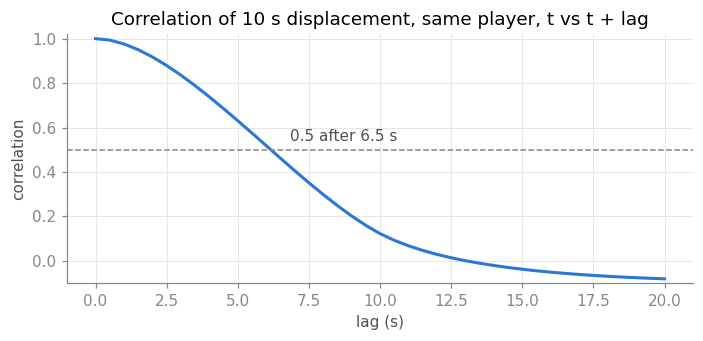

correlation < 0.5 after 13 steps (6.5 s): roughly train 176,614, val 21,157, test 22,986 effectively independent windows


In [8]:
dx, dy = x[j20] - x, y[j20] - y
lags = np.arange(0, 41)
corr = []
for k in lags:
    i = np.flatnonzero(ok20 & (step + k + HORIZON < n))
    i = i[ok20[i + k]]
    a, b = np.r_[dx[i], dy[i]], np.r_[dx[i + k], dy[i + k]]
    corr.append(np.corrcoef(a, b)[0, 1])
corr = np.array(corr)
half = int(lags[np.argmax(corr < 0.5)])
eff = {s: sizes.loc[s, "windows"] / half for s in SPLITS}

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(lags * STEP_SECONDS, corr, color=COLORS["all"], linewidth=2)
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"0.5 after {half * STEP_SECONDS:g} s", (half * STEP_SECONDS, 0.5), xytext=(6, 6), textcoords="offset points", color=INK)
ax.set(title="Correlation of 10 s displacement, same player, t vs t + lag", xlabel="lag (s)", ylabel="correlation", ylim=(-0.1, 1.02))
plt.tight_layout(); plt.show()
print(f"correlation < 0.5 after {half} steps ({half * STEP_SECONDS:g} s): roughly "
      + ", ".join(f"{s} {eff[s]:,.0f}" for s in SPLITS) + " effectively independent windows")

**How precise are test metrics?** Windows from one match are correlated (same players, same strategies), so the
honest confidence interval comes from resampling **matches**, not windows. Below: 95% bootstrap CIs of the
two simplest baselines' error at 10 s on the test split, and of their paired difference. A model improvement smaller
than these half-widths is indistinguishable from noise on this test set. Comparing two models on the same windows
(paired) is much tighter than comparing two independent CIs.

In [9]:
rng = np.random.default_rng(0)
test = ok20 & (ps["split"].to_numpy() == "test")
per_match = pd.DataFrame({"match": ps["match"].to_numpy()[test], "stay": disp10[test], "cv": cv10[test]})
per_match["diff"] = per_match["stay"] - per_match["cv"]
g = per_match.groupby("match")
sums, cnt = g[["stay", "cv", "diff"]].sum().to_numpy(), g.size().to_numpy()
B = 2000
idx = rng.integers(0, len(cnt), size=(B, len(cnt)))
boot = sums[idx].sum(1) / cnt[idx].sum(1)[:, None]  # [B, 3] pooled means over resampled matches
naive_se = per_match[["stay", "cv", "diff"]].std() / np.sqrt(len(per_match))
ci = pd.DataFrame({
    "mean error at 10 s (units)": per_match[["stay", "cv", "diff"]].mean().to_numpy(),
    "95% CI, resample matches": [f"{lo:.0f} - {hi:.0f}" for lo, hi in np.percentile(boot, [2.5, 97.5], axis=0).T],
    "± half-width, matches": (np.percentile(boot, 97.5, axis=0) - np.percentile(boot, 2.5, axis=0)) / 2,
    "± half-width, naive (iid windows)": 1.96 * naive_se.to_numpy(),
}, index=["stay still", "constant velocity", "stay - const. vel. (paired)"])
ci["± relative"] = (ci["± half-width, matches"] / ci["mean error at 10 s (units)"].abs()).map("{:.1%}".format)
print(f"test: {len(cnt)} matches, {test.sum():,} (window, player) targets alive at 10 s")
display(ci.style.format({c: "{:.1f}" for c in ci.columns if "half" in c or "mean" in c}))

test: 41 matches, 979,034 (window, player) targets alive at 10 s


,mean error at 10 s (units),"95% CI, resample matches","± half-width, matches","± half-width, naive (iid windows)",± relative
stay still,588.5,575 - 605,14.8,1.0,2.5%
constant velocity,1073.8,1055 - 1097,21.0,1.5,2.0%
stay - const. vel. (paired),-485.3,-496 - -474,10.9,1.4,2.3%


## 3. Leakage between splits

Splits are assigned per match id, so no match is in two splits. Players, teams and opponents still recur, which
lets a model score well on test by memorizing tendencies. The checks below look for that, and for the same game
saved twice under different names (identical round timings and roster).

In [10]:
roster = sql("""SELECT d.split, d.file, d.match, r.round_id, rp.steamid FROM round_players rp
                  JOIN rounds r USING (round_id) JOIN demos d USING (demo_id)""")
train_players = set(roster.loc[roster["split"] == "train", "steamid"])
demo_teams = sql("""SELECT d.file, d.match, d.split, MIN(r.t_team) AS a, MAX(r.t_team) AS b
                      FROM rounds r JOIN demos d USING (demo_id) GROUP BY d.demo_id""")
demo_teams["pair"] = [tuple(sorted(p)) for p in zip(demo_teams["a"], demo_teams["b"])]
train_teams = set(demo_teams.loc[demo_teams["split"] == "train", ["a", "b"]].to_numpy().ravel())
train_pairs = set(demo_teams.loc[demo_teams["split"] == "train", "pair"])
leak = {}
for split in ("val", "test"):
    r = roster[roster["split"] == split]
    dt = demo_teams[demo_teams["split"] == split]
    leak[split] = {
        "player-rounds by a player also in train": f"{r['steamid'].isin(train_players).mean():.1%}",
        "demos where both teams appear in train": f"{(dt['a'].isin(train_teams) & dt['b'].isin(train_teams)).mean():.1%}",
        "demos whose exact matchup is in train": f"{dt['pair'].isin(train_pairs).sum()} / {len(dt)}",
    }
display(pd.DataFrame(leak))

same = demo_teams[demo_teams["split"] != "train"].merge(
    demo_teams[demo_teams["split"] == "train"], on="pair", suffixes=("", "_train"))
print("Held-out demos whose matchup also appears in train (same series split apart, or a rematch):")
display(same[["split", "file", "file_train"]].sort_values("file").reset_index(drop=True))

sig = sql("""SELECT d.file, d.split, GROUP_CONCAT(r.end_tick - r.freeze_end_tick, ',') AS sig
               FROM (SELECT * FROM rounds ORDER BY demo_id, round_num) r JOIN demos d USING (demo_id) GROUP BY d.demo_id""")
dups = sig[sig.duplicated("sig", keep=False)].sort_values("sig")
print(f"demos with an identical round-timing signature to another demo: {len(dups)}")
if len(dups):
    display(dups[["file", "split"]])

,val,test
player-rounds by a player also in train,87.9%,86.5%
demos where both teams appear in train,75.6%,68.2%
demos whose exact matchup is in train,2 / 41,4 / 44


Held-out demos whose matchup also appears in train (same series split apart, or a rematch):


,split,file,file_train
0,val,lfo-10-vs-maybe-m1-mirage.npz,maybe-vs-lfo-10-m2-mirage.npz
1,test,mellren-vs-spirit-academy-m2-mirage.npz,spirit-academy-vs-mellren-m2-mirage.npz
2,test,mellren-vs-spirit-academy-m2-mirage_1.npz,spirit-academy-vs-mellren-m2-mirage.npz
3,test,overtake-sector-vs-chicken-coop-m1-mirage.npz,chicken-coop-vs-overtake-sector-m1-mirage.npz
4,test,pain-vs-naocopulas-m2-mirage.npz,naocopulas-vs-pain-m1-mirage.npz
5,val,the-mongolz-vs-big-m2-mirage.npz,big-vs-the-mongolz-m3-mirage.npz


demos with an identical round-timing signature to another demo: 0


## 4. The target

**How much of the 10 s target exists?** The share of (window, player) samples whose target is still valid *k* steps
ahead. Death and round end mask the rest. Late horizons are fewer and biased toward players who survive, so
FDE@10 s is computed on a different, easier-or-harder population than FDE@1 s.

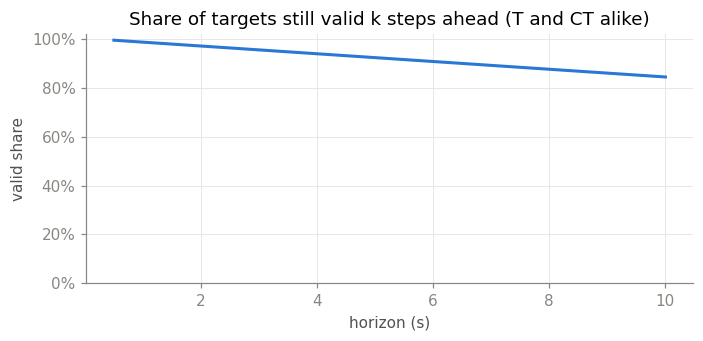

,t,ct
1 s,98.7%,98.8%
3 s,95.5%,95.6%
5 s,92.3%,92.5%
10 s,84.3%,84.6%


In [11]:
coverage = {}
side = ps["side"].to_numpy()
for k in range(1, HORIZON + 1):
    _, ok = future(k)
    coverage[k] = {s: ok[side == s].sum() / anchor[side == s].sum() for s in SIDES}
coverage = pd.DataFrame(coverage).T
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(coverage.index * STEP_SECONDS, coverage.mean(1), color=COLORS["all"], linewidth=2)  # T and CT are within 0.5 pp
ax.set(title="Share of targets still valid k steps ahead (T and CT alike)", xlabel="horizon (s)", ylabel="valid share", ylim=(0, 1.02))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()
display(coverage.loc[[2, 6, 10, 20]].rename(index=lambda k: f"{k * STEP_SECONDS:g} s").style.format("{:.1%}"))

**How far do players move?** Distance between now and *k* seconds ahead (this is also the stay-still error). A big
stationary share means a model can score well by predicting "holds the angle" and mostly has to get the movers right.
Breaking metrics out by "moving at *t*" (as baselines does) matters for that reason.

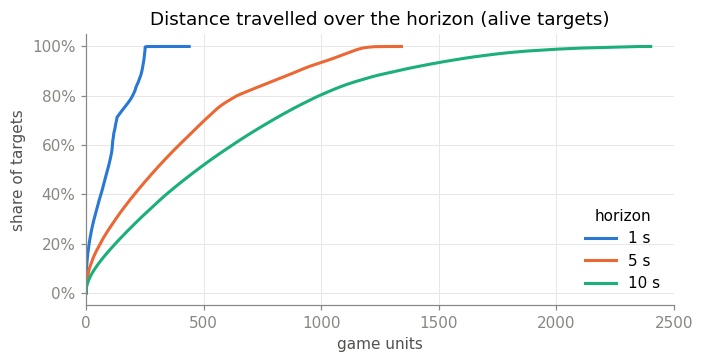

,median,p90,< 100 units,> 1000 units
1 s,91,236,53.6%,0.0%
5 s,295,900,26.4%,6.5%
10 s,472,1317,17.5%,19.6%


at the anchor step, 57.1% of alive players are moving > 100 u/s; of the stationary ones, 30.8% are still within 100 units 10 s later


In [12]:
rows = {}
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, color in zip((2, 10, 20), ("#2a78d6", "#eb6834", "#1baf7a")):
    j, ok = future(k)
    d = np.hypot(x[j] - x, y[j] - y)[ok]
    q = np.sort(d)
    ax.plot(q, np.linspace(0, 1, len(q)), color=color, linewidth=2, label=f"{k * STEP_SECONDS:g} s")
    rows[f"{k * STEP_SECONDS:g} s"] = {"median": np.median(d), "p90": np.percentile(d, 90),
                                       "< 100 units": f"{(d < 100).mean():.1%}", "> 1000 units": f"{(d > 1000).mean():.1%}"}
ax.set(title="Distance travelled over the horizon (alive targets)", xlabel="game units", ylabel="share of targets", xlim=(0, 2500))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title="horizon", frameon=False)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).T.style.format({"median": "{:.0f}", "p90": "{:.0f}"}))
moving_now = np.hypot(vx, vy) > 100
print(f"at the anchor step, {moving_now[ok20].mean():.1%} of alive players are moving > 100 u/s; "
      f"of the stationary ones, {(disp10[ok20 & ~moving_now] < 100).mean():.1%} are still within 100 units 10 s later")

## 5. What the team-perspective masking hides

For each alive player, from the enemy team's point of view: is their current position known (visible), only a stale
last-seen position, or nothing at all? How wrong is the last-seen position as a guess of where they are now?
This is the information gap the full-information ablation (`mask_enemies=False`) closes.

In [13]:
seen_age = ps["seen_age"].to_numpy()
vis = ps["visible"].to_numpy() == 1
known = ~np.isnan(seen_age)
stale = alive & ~vis & known
err = np.hypot(ps["last_seen_x"].to_numpy() - x, ps["last_seen_y"].to_numpy() - y)
display(pd.Series({
    "visible now": f"{(vis & alive).sum() / alive.sum():.1%}",
    "not visible, seen earlier this round": f"{stale.sum() / alive.sum():.1%}",
    "never seen this round": f"{(alive & ~known).sum() / alive.sum():.1%}",
    "median age of the last sighting (stale)": f"{np.median(seen_age[stale]):.1f} s",
}, name="share of alive enemy-steps").to_frame())
buckets = pd.cut(seen_age[stale], [0, 1, 3, 10, 30, 200], labels=["<1 s", "1-3 s", "3-10 s", "10-30 s", ">30 s"])
by_age = pd.DataFrame({"age": buckets, "err": err[stale]}).groupby("age", observed=True)["err"]
display(pd.DataFrame({"share of stale": by_age.size() / stale.sum(), "median error (units)": by_age.median(),
                      "p90 error": by_age.quantile(0.9)}).style.format({"share of stale": "{:.1%}", "median error (units)": "{:.0f}", "p90 error": "{:.0f}"}))

,share of alive enemy-steps
visible now,1.4%
"not visible, seen earlier this round",12.6%
never seen this round,86.1%
median age of the last sighting (stale),14.4 s


,share of stale,median error (units),p90 error
age,,,
<1 s,3.4%,56,132
1-3 s,10.7%,142,339
3-10 s,25.0%,331,825
10-30 s,36.2%,679,1629
>30 s,24.7%,1169,2427


**Is the visibility signal trustworthy?** Visibility comes from demoparser's `approximate_spotted_by`. Nearly every kill
needs line of sight (exceptions: grenade/fire damage, wallbangs, smoke kills), so a player who dies should almost
always be visible to the enemy in the half second or two before death. A low rate here means the masking hides more
than a real team would lose.

In [14]:
i = np.flatnonzero(~alive & (step > 0))
i = i[alive[i - 1]]  # the step at which a player dies
vis_at_death = vis[i] | vis[i - 1]
vis_2s = vis_at_death | vis[np.maximum(i - 2, 0)] | vis[np.maximum(i - 3, 0)] | vis[np.maximum(i - 4, 0)]
spotted_rate = sql("SELECT AVG(spotted) AS s, AVG(visible) AS v FROM player_steps WHERE is_alive = 1 AND round_id % 10 = 0")
display(pd.Series({
    "deaths (val + test)": f"{len(i):,}",
    "victim visible to the enemy within 0.5 s of death": f"{vis_at_death.mean():.1%}",
    "... within 2 s of death": f"{vis_2s.mean():.1%}",
    "alive steps with the game's `spotted` flag set (all splits)": f"{spotted_rate['s'].iloc[0]:.1%}",
    "alive steps with `visible` set (all splits)": f"{spotted_rate['v'].iloc[0]:.1%}",
}).to_frame("value"))

,value
deaths (val + test),"10,612"
victim visible to the enemy within 0.5 s of death,61.3%
... within 2 s of death,64.5%
alive steps with the game's `spotted` flag set (all splits),0.9%
alive steps with `visible` set (all splits),1.3%


## 6. Evaluation slices: are they big enough?

Test windows split by situation, with the number of matches behind each slice and how hard it is (stay-still error
at 10 s). A slice backed by only a handful of matches can't support a per-slice claim. Buy type is the POV team's
equipment value at freeze end; pistol rounds are rounds 1 and 13.

In [15]:
rs = sql("""SELECT rs.round_id, rs.step, rs.bomb_planted, rs.t_alive, rs.ct_alive, rs.t_equip_value, rs.ct_equip_value
              FROM round_steps rs JOIN rounds USING (round_id) JOIN demos d USING (demo_id) WHERE d.split = 'test'""")
start = rs[rs["step"] == 0].set_index("round_id")[["t_equip_value", "ct_equip_value"]]
t_mask = ok20 & (ps["split"].to_numpy() == "test")
samples = pd.DataFrame({"round_id": ps["round_id"].to_numpy()[t_mask], "step": step[t_mask], "side": side[t_mask],
                        "match": ps["match"].to_numpy()[t_mask], "round_num": ps["round_num"].to_numpy()[t_mask],
                        "err": disp10[t_mask], "moving": moving_now[t_mask]})
samples = samples.merge(rs[["round_id", "step", "bomb_planted", "t_alive", "ct_alive"]], on=["round_id", "step"])
is_t = samples["side"] == "t"
samples["own_alive"] = np.where(is_t, samples["t_alive"], samples["ct_alive"])
samples["enemy_alive"] = np.where(is_t, samples["ct_alive"], samples["t_alive"])
equip = np.where(is_t, start.loc[samples["round_id"], "t_equip_value"], start.loc[samples["round_id"], "ct_equip_value"])
samples["buy"] = np.select([samples["round_num"].isin([1, 13]), equip < 10000, equip < 20000],
                           ["pistol", "eco (< $10k)", "force ($10-20k)"], "full buy (>= $20k)")
samples["phase"] = np.where(samples["bomb_planted"] == 1, "post-plant", "pre-plant")
adv = (samples["own_alive"] - samples["enemy_alive"]).clip(-2, 2)
samples["man advantage"] = adv.map({-2: "-2 or worse", -1: "-1", 0: "even", 1: "+1", 2: "+2 or better"})

out = []
for col in ("side", "phase", "buy", "man advantage"):
    g = samples.groupby(col)
    out.append(pd.DataFrame({"slice": col, "targets": g.size(), "share": g.size() / len(samples),
                             "matches": g["match"].nunique(), "moving at t": g["moving"].mean(),
                             "stay-still error at 10 s": g["err"].mean()}))
slices = pd.concat(out).reset_index(names="value").set_index(["slice", "value"])
display(slices.style.format({"targets": "{:,}", "share": "{:.1%}", "moving at t": "{:.0%}", "stay-still error at 10 s": "{:.0f}"}))

## 7. Data-quality issues

**Bomb site labels.** `plant_site_a` is never set, so every plant is stored as B. `build_dataset.py` takes the site
from awpy's `rounds.bomb_site`, and awpy calls a plant A only if the bombsite entity id is 220, which these demos don't
use. The bomb's position separates the sites: A is in the south of the map (y < -1000), B in the north-west.
These flags are model inputs (`plant_site_a`, `plant_site_b` in `GLOBAL_INPUTS`).

In [16]:
plants = sql("""SELECT round_id, MAX(plant_site_a) AS flag_a, MAX(plant_site_b) AS flag_b,
                        MIN(CASE WHEN bomb_planted = 1 THEN bomb_y END) AS bomb_y
                 FROM round_steps GROUP BY round_id HAVING MAX(bomb_planted) = 1""")
plants["site from bomb position"] = np.where(plants["bomb_y"] < -1000, "A", "B")
display(pd.crosstab(plants["site from bomb position"], [plants["flag_a"].rename("plant_site_a"), plants["flag_b"].rename("plant_site_b")]))

plant_site_a,0
plant_site_b,1
site from bomb position,
A,2577
B,1536


## Key findings (as of the last run: 420 demos, 402 matches)

- **Windows: 2,869,840** (2.30M train / 275k val / 299k test). They are heavily autocorrelated: a player's 10 s
  displacement only decorrelates below 0.5 after ~6.5 s (13 steps), so there are about **23k effectively independent test
  windows**. Each epoch is mostly re-seeing near-duplicates; subsampling windows (e.g. every 4th step) would cost little signal.
- **Test precision:** with 41 test matches, a pooled 10 s error has a **±2-2.5% match-level 95% CI**. Window-level (iid)
  CIs are ~15x too narrow. Report match-bootstrapped CIs, and compare models paired on the same windows.
- **Leakage:** 87% of val/test player-rounds are by players who also appear in train, and ~70% of held-out demos have
  both teams in train. The test set measures generalisation to new *games* by mostly familiar players, not to new players.
  No duplicate demos. 6 held-out demos are rematches of a train matchup (different games, not mis-split series).
- **Target coverage:** 84% of targets are still valid at 10 s (death/round end mask the rest), equal for T and CT.
- **Visibility looks undercounted.** Only ~61% of victims are visible to the enemy within 0.5 s of their death, and
  86% of alive enemy-steps are "never seen this round". In real games almost every kill needs line of sight, so the
  enemy masking probably hides far more than a real team would lose. This is the biggest open question about the
  inputs; check `approximate_spotted_by` parsing in `build_dataset.py` before trusting masked-vs-full-info comparisons.
- **Bomb site flags are wrong:** every plant is stored as `plant_site_b`. About 63% are really A. Needs a fix in
  `build_dataset.py` (site from the bomb position or the planter's place) and a rebuild of `processed/` and `mirage.db`.
- **Slices:** every side / phase / buy / man-advantage slice has ≥ 40 test matches, so per-slice metrics are reportable.
  Post-plant is only 7% of targets.

In [17]:
print(f"Total windows: {TOTAL_WINDOWS:,}")
print(f"Notebook runtime: {time.perf_counter() - NOTEBOOK_START:.0f}s")
conn.close()

Total windows: 2,869,840
Notebook runtime: 60s
